# ShoreSense - Module 2: Report Understanding (NLP)

## Install

## Imports

In [1]:
import os
import string
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\nilofer.mubeen\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\nilofer.mubeen\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\nilofer.mubeen\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\nilofer.mubeen\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\nilofer.mubeen\AppData\Roaming\nltk_data...


True

## Load Data

In [2]:
df = pd.read_csv(r"data\nlp\reports.csv")
stress_df = pd.read_csv(r"data\nlp\hard_reports.csv")
print(df.shape, stress_df.shape)
df.head()

(1500, 8) (30, 7)


,id,text,species,location,condition,gear,urgency,split
0,0,found a right whale off marina beach chennai i...,north_atlantic_right_whale,Marina Beach Chennai,healthy,none,low,test
1,1,The turtle looks fine and is moving normally. ...,green_turtle,Malim Jetty Goa,healthy,none,low,train
2,2,"Urgent! A baby animal, the animal has a wound ...",unknown,unknown,injured,none,high,train
3,3,Found a dolphin at Cape Cod. The animal is cau...,bottlenose_dolphin,Cape Cod,entangled,fishing_net,high,train
4,4,the dolphin is caught in a rope we saw a dolph...,bottlenose_dolphin,Cape Cod,entangled,rope,high,train


## Class Balance of Each Target

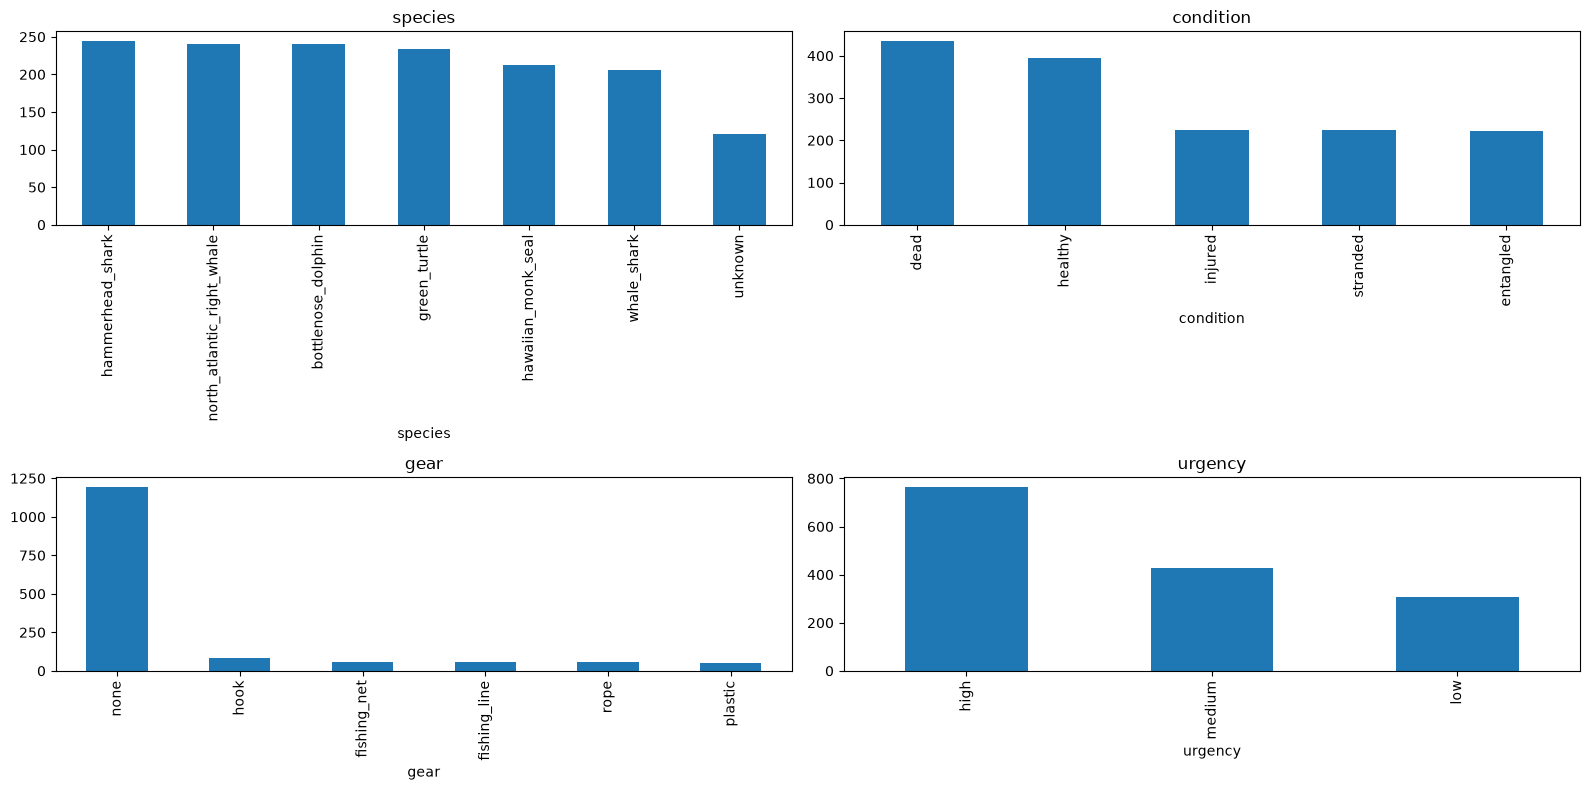

In [3]:
targets = ["species", "condition", "gear", "urgency"]

plt.figure(figsize=(16, 8))
for i, t in enumerate(targets):
    plt.subplot(2, 2, i + 1)
    df[t].value_counts().plot(kind="bar")
    plt.title(t)
plt.tight_layout()
plt.show()

## Report Length

In [4]:
df["length"] = df["text"].str.split().str.len()
df["length"].describe()

count    1500.000000
mean       15.283333
std         3.197792
min         7.000000
25%        13.000000
50%        15.000000
75%        17.000000
max        29.000000
Name: length, dtype: float64

## Ten Example Reports

In [5]:
df.sample(10, random_state=1)[["text", "species", "condition", "gear", "urgency"]]

,text,species,condition,gear,urgency
91,A creature at Kozhikode. It washed up and cann...,unknown,stranded,none,high
75,Found a monk seal near Kanyakumari. The animal...,hawaiian_monk_seal,dead,none,medium
1264,The bottlenose dolphin is swimming close to sh...,bottlenose_dolphin,healthy,none,low
330,"urgent! a monk seal at maui, the animal is lyi...",hawaiian_monk_seal,stranded,none,high
1349,"Urgent! A whale shark at Outer Banks, the whal...",whale_shark,dead,none,medium
774,The whale shark is swimming close to shore. We...,whale_shark,healthy,none,medium
1038,a bottlenose dolphin at cape cod the animal se...,bottlenose_dolphin,dead,none,medium
1285,Found a dolphin near Kauai. The dolphin looks ...,bottlenose_dolphin,dead,none,medium
1165,Found a baby dolphin near Hilo. The animal loo...,bottlenose_dolphin,healthy,none,medium
335,the hammerhead looks fine and is moving normal...,hammerhead_shark,healthy,none,low


## Text Cleaning

In [6]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()
    text = text.translate(str.maketrans("", "", string.punctuation))
    tokens = word_tokenize(text)
    tokens = [w for w in tokens if w not in stop_words]
    tokens = [lemmatizer.lemmatize(w) for w in tokens]
    return " ".join(tokens)

## Create Clean Text Column

In [7]:
df["clean_text"] = df["text"].apply(clean_text)
df[["text", "clean_text"]].head()

,text,clean_text
0,found a right whale off marina beach chennai i...,found right whale marina beach chennai swimmin...
1,The turtle looks fine and is moving normally. ...,turtle look fine moving normally saw turtle ma...
2,"Urgent! A baby animal, the animal has a wound ...",urgent baby animal animal wound near tail
3,Found a dolphin at Cape Cod. The animal is cau...,found dolphin cape cod animal caught gill net
4,the dolphin is caught in a rope we saw a dolph...,dolphin caught rope saw dolphin cape cod


## Train Test Split

In [8]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["urgency"])
print(train_df.shape, test_df.shape)

(1200, 10) (300, 10)


## TF-IDF

In [9]:
tfidf = TfidfVectorizer()
X_train = tfidf.fit_transform(train_df["clean_text"])
X_test = tfidf.transform(test_df["clean_text"])

## Compare Models for Each Target

In [10]:
def get_model(name):
    if name == "LogisticRegression":
        return LogisticRegression(max_iter=1000)
    return MultinomialNB()

best_models = {}
rows = []

for target in targets:
    best_f1 = -1
    for name in ["LogisticRegression", "NaiveBayes"]:
        model = get_model(name)
        model.fit(X_train, train_df[target])
        pred = model.predict(X_test)
        acc = accuracy_score(test_df[target], pred)
        f1 = f1_score(test_df[target], pred, average="macro")
        rows.append([target, name, acc, f1])
        if f1 > best_f1:
            best_f1 = f1
            best_models[target] = model

pd.DataFrame(rows, columns=["target", "model", "accuracy", "macro_f1"])

,target,model,accuracy,macro_f1
0,species,LogisticRegression,0.996667,0.994957
1,species,NaiveBayes,0.960000,0.932129
2,condition,LogisticRegression,1.000000,1.000000
3,condition,NaiveBayes,1.000000,1.000000
4,gear,LogisticRegression,1.000000,1.000000
5,gear,NaiveBayes,0.993333,0.986680
6,urgency,LogisticRegression,0.933333,0.930060
7,urgency,NaiveBayes,0.903333,0.895098


## Classification Reports

In [11]:
for target in targets:
    print("=====", target, "=====")
    pred = best_models[target].predict(X_test)
    print(classification_report(test_df[target], pred))

===== species =====
                            precision    recall  f1-score   support

        bottlenose_dolphin       1.00      1.00      1.00        48
              green_turtle       1.00      0.98      0.99        42
          hammerhead_shark       1.00      1.00      1.00        54
        hawaiian_monk_seal       1.00      1.00      1.00        39
north_atlantic_right_whale       1.00      1.00      1.00        47
                   unknown       0.95      1.00      0.98        21
               whale_shark       1.00      1.00      1.00        49

                  accuracy                           1.00       300
                 macro avg       0.99      1.00      0.99       300
              weighted avg       1.00      1.00      1.00       300

===== condition =====
              precision    recall  f1-score   support

        dead       1.00      1.00      1.00        80
   entangled       1.00      1.00      1.00        48
     healthy       1.00      1.00      1.00 

## Urgency Confusion Matrix

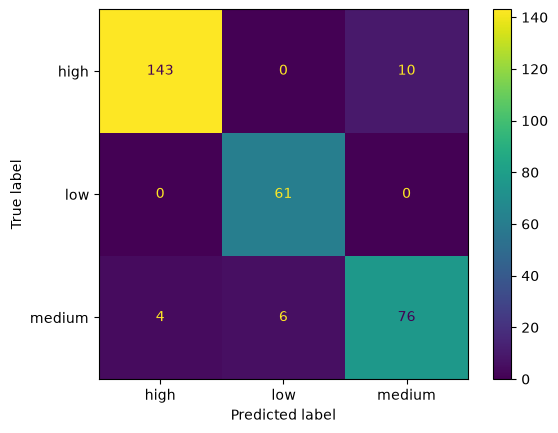

In [12]:
pred = best_models["urgency"].predict(X_test)
ConfusionMatrixDisplay.from_predictions(test_df["urgency"], pred)
plt.show()

## Error Analysis

In [13]:
errors = test_df.copy()
errors["predicted_urgency"] = pred
errors = errors[errors["urgency"] != errors["predicted_urgency"]]
errors[["text", "condition", "urgency", "predicted_urgency"]].head(15)

,text,condition,urgency,predicted_urgency
1309,Found a baby right whale at Galveston. The rig...,dead,high,medium
1419,The bottlenose dolphin looks fine and is movin...,healthy,medium,low
414,the animal is resting on the sand we saw a bab...,healthy,medium,high
925,"The right whale looks dead, not moving or brea...",dead,high,medium
37,Urgent! A baby dolphin on the beach at Outer B...,dead,high,medium
483,found a baby seal at marina beach chennai it l...,dead,high,medium
1007,Found a baby right whale at Rameswaram. The ri...,healthy,medium,low
1468,The animal is dead. We saw a baby hammerhead s...,dead,high,medium
1025,Found a baby seal on the beach at Galveston. I...,dead,high,medium
1320,found a baby right whale around mandapam the a...,healthy,medium,high


## Stress Test on test_reports.csv

In [14]:
stress_df["clean_text"] = stress_df["text"].apply(clean_text)
X_stress = tfidf.transform(stress_df["clean_text"])

rows = []
for target in targets:
    pred = best_models[target].predict(X_stress)
    acc = accuracy_score(stress_df[target], pred)
    f1 = f1_score(stress_df[target], pred, average="macro")
    rows.append([target, acc, f1])

pd.DataFrame(rows, columns=["target", "accuracy", "macro_f1"])

,target,accuracy,macro_f1
0,species,0.833333,0.829278
1,condition,0.666667,0.670080
2,gear,0.766667,0.655271
3,urgency,0.700000,0.578010


## Save Models

In [15]:
os.makedirs("models", exist_ok=True)
joblib.dump(tfidf, "models/tfidf.pkl")
joblib.dump(best_models, "models/nlp_models.pkl")

['models/nlp_models.pkl']

## Extract Report Function

In [16]:
def extract_report(text):
    clean = clean_text(text)
    vector = tfidf.transform([clean])
    result = {}
    for target in targets:
        result[target] = best_models[target].predict(vector)[0]
    return result

## Try the Function

In [17]:
extract_report("a baby dolphin tangled in fishing net on the beach, not moving much")

{'species': 'bottlenose_dolphin',
 'condition': 'entangled',
 'gear': 'fishing_net',
 'urgency': 'high'}